# Model 1: Linear Regression Baseline
### B.Tech Mini Project: Aircraft Engine Predictive Maintenance (NASA C-MAPSS FD001)

This notebook builds **Model 1 (Linear Regression)** as part of our controlled five-model architectural benchmark:
1. **Linear Regression (Baseline)** *(this notebook)*
2. **Random Forest**
3. **LSTM**
4. **GRU**
5. **1D-CNN**

#### Workflow Stages:
1. **Stage 1 - Reproduce Preprocessed Dataset:** Self-contained loading, labeling, engine-wise 80/20 splitting, zero-variance pruning, scaling, and sequence windowing ($W=30$).
2. **Stage 2 - Theoretical Context:** Understand how Linear Regression models RUL, its purpose as an anchor baseline, and why tensor flattening is required.
3. **Stage 3 - Feature Flattening:** Transform 3D sequence tensors `(N, 30, 17)` into 2D matrices `(N, 510)` for linear modeling while preserving original 3D tensors.
4. **Stage 4 - Model Training:** Fit `LinearRegression` strictly on the training partition.
5. **Stage 5 - Metrics Formulation:** Implement Root Mean Squared Error (RMSE) and the asymmetric NASA Scoring function.
6. **Stage 6 - Visualizations:** Plot actual vs. predicted validation scatter, residual distribution, and summary metrics table.
7. **Stage 7 - Interpretation & Validation Checks:** Examine bias/variance tradeoffs, generalization, and structural limitations.

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Visual styling for academic figures
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

print("NumPy version :", np.__version__)
print("Pandas version:", pd.__version__)
print("Environment initialized successfully.")

NumPy version : 2.5.4
Pandas version: 3.1.0
Environment initialized successfully.


---
## Stage 1: Reproduce the Prepared Dataset

To ensure this notebook executes independently in an isolated kernel, we recreate the exact preprocessing and sequence generation pipeline from notebooks `04` and `05`:
1. Ingest `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` with standard 26-column naming.
2. Generate capped training RUL labels using $RUL = \min(125, \max(\text{cycle}) - \text{cycle})$.
3. Split engine IDs ($80\%$ train, $20\%$ validation) with `random_state=42`.
4. Prune the 7 zero-variance features on the training split while retaining `sensor_6` (17 features selected).
5. Fit `StandardScaler` strictly on the training partition and standardize train, validation, and test sets.
6. Generate 30-cycle sliding sequences ($W=30$, stride=1) for training and validation, and final 30-cycle windows for test engines.

In [9]:
# 1. Define schema
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# 2. Resolve data directory
DATA_DIR = Path("../data/raw/CMaps") if Path("../data/raw/CMaps").exists() else Path("data/raw/CMaps")

# 3. Ingest raw datasets
train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_df = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_df = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# 4. Calculate piecewise linear capped RUL (cap = 125)
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")
train_df["raw_RUL"] = train_df["max_cycle"] - train_df["cycle"]
train_df["RUL"] = np.minimum(125, train_df["raw_RUL"])

# 5. Engine-wise split (80 train units, 20 validation units, random_state=42)
unique_units = train_df["unit"].unique()
train_units, val_units = train_test_split(unique_units, test_size=0.20, random_state=42)

train_split_df = train_df[train_df["unit"].isin(train_units)].copy().reset_index(drop=True)
val_split_df = train_df[train_df["unit"].isin(val_units)].copy().reset_index(drop=True)

# 6. Feature selection strictly on training partition
candidate_features = [f"op_setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
train_var = train_split_df[candidate_features].var()
train_nunique = train_split_df[candidate_features].nunique()
zero_var_features = [f for f in candidate_features if train_nunique[f] == 1 or train_var[f] < 1e-12]
selected_features = [f for f in candidate_features if f not in zero_var_features]

# 7. Fit StandardScaler strictly on training partition
scaler = StandardScaler()
train_split_df[selected_features] = scaler.fit_transform(train_split_df[selected_features])
val_split_df[selected_features] = scaler.transform(val_split_df[selected_features])
test_df[selected_features] = scaler.transform(test_df[selected_features])

# 8. Sliding window extraction (Window size = 30 cycles)
WINDOW_SIZE = 30

def extract_windows(df, seq_len, feature_cols, target_col="RUL"):
    X_list, y_list = [], []
    for unit, group in df.groupby("unit"):
        group_sorted = group.sort_values("cycle").reset_index(drop=True)
        features = group_sorted[feature_cols].values
        targets = group_sorted[target_col].values
        for i in range(len(group_sorted) - seq_len + 1):
            X_list.append(features[i : i + seq_len])
            y_list.append(targets[i + seq_len - 1])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = extract_windows(train_split_df, WINDOW_SIZE, selected_features)
X_val, y_val = extract_windows(val_split_df, WINDOW_SIZE, selected_features)

# Final 30-cycle window for each of the 100 test engines (retained, not evaluated yet)
X_test_list = []
for unit, group in test_df.groupby("unit"):
    group_sorted = group.sort_values("cycle").reset_index(drop=True)
    X_test_list.append(group_sorted[selected_features].values[-WINDOW_SIZE:])
X_test = np.array(X_test_list, dtype=np.float32)

# Assertions verifying exact match with notebook 05
assert X_train.shape == (14241, 30, 17), f"X_train shape mismatch: {X_train.shape}"
assert X_val.shape == (3490, 30, 17), f"X_val shape mismatch: {X_val.shape}"
assert X_test.shape == (100, 30, 17), f"X_test shape mismatch: {X_test.shape}"
assert y_train.shape == (14241,), f"y_train shape mismatch: {y_train.shape}"
assert y_val.shape == (3490,), f"y_val shape mismatch: {y_val.shape}"
assert len(selected_features) == 17, f"Selected features mismatch: {len(selected_features)}"

print("=" * 65)
print("STAGE 1: DATASET REPRODUCED & SHAPES CONFIRMED")
print("=" * 65)
print(f"X_train shape : {X_train.shape}  | y_train shape : {y_train.shape}")
print(f"X_val shape   : {X_val.shape}   | y_val shape   : {y_val.shape}")
print(f"X_test shape  : {X_test.shape}    | (retained for final test evaluation)")
print(f"Selected Features ({len(selected_features)}): {selected_features}")
print("=" * 65)

STAGE 1: DATASET REPRODUCED & SHAPES CONFIRMED
X_train shape : (14241, 30, 17)  | y_train shape : (14241,)
X_val shape   : (3490, 30, 17)   | y_val shape   : (3490,)
X_test shape  : (100, 30, 17)    | (retained for final test evaluation)
Selected Features (17): ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


---
## Stage 2: Understanding Linear Regression for RUL Prediction

### What is Linear Regression?
Linear Regression is a foundational parametric machine learning algorithm that models the target variable $y$ (Remaining Useful Life) as a linear combination of input features $x = [x_1, x_2, \dots, x_P]^T$:
$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_P x_P = w_0 + \mathbf{w}^T \mathbf{x}$$

### How it Learns from Telemetry Data
Using Ordinary Least Squares (OLS), the algorithm finds the weight vector $\mathbf{w}$ that minimizes the Residual Sum of Squares (RSS):
$$J(\mathbf{w}) = \sum_{i=1}^N (y_i - \hat{y}_i)^2 = \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2$$
In closed form, $\mathbf{w} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$. Each learned weight $w_j$ represents the expected change in remaining cycles associated with a one-standard-deviation change in feature $j$.

### Why is Linear Regression Essential as Model 1?
1. **Baseline Benchmark:** It serves as the reference lower bound. Any sophisticated deep learning model (e.g., LSTM, GRU, 1D-CNN) introduces architectural complexity and training cost that is only justifiable if it decisively outperforms this simple linear model.
2. **Computational Speed & Simplicity:** It trains deterministically in milliseconds without requiring GPUs, hyperparameter tuning, or stochastic optimization.

### Why Can't it Directly Accept 3D Sequence Tensors?
Standard Linear Regression is designed strictly for **2D tabular matrices** of shape `(n_samples, n_features)`. It has no concept of temporal recurrence, time steps, or sequence ordering. To input a $30 \times 17$ sequence window into Linear Regression, we must **flatten** each 2D window into a single 1D feature vector of length $30 \times 17 = 510$.

---
## Stage 3: Prepare Input Features (Flattening)

We reshape the 3D window tensors into 2D feature matrices:
- `X_train`: `(14241, 30, 17)` $\rightarrow$ `X_train_flat`: `(14241, 510)`
- `X_val`: `(3490, 30, 17)` $\rightarrow$ `X_val_flat`: `(3490, 510)`

Each observation represents a window of 30 cycles, where the 510 features represent:
$$[\text{feature}_1(t-29), \dots, \text{feature}_{17}(t-29), \dots, \text{feature}_1(t), \dots, \text{feature}_{17}(t)]$$

The original 3D tensors (`X_train`, `X_val`, `X_test`) are preserved unaltered for subsequent sequence models.

In [10]:
# Flatten 3D window arrays into 2D matrices
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)

# Verify dimensions
assert X_train_flat.shape == (14241, 510), f"X_train_flat shape error: {X_train_flat.shape}"
assert X_val_flat.shape == (3490, 510), f"X_val_flat shape error: {X_val_flat.shape}"
assert X_train.shape == (14241, 30, 17), "Original X_train was unintentionally modified!"
assert X_val.shape == (3490, 30, 17), "Original X_val was unintentionally modified!"

print("=" * 65)
print("STAGE 3: INPUT FEATURE FLATTENING")
print("=" * 65)
print(f"X_train original shape : {X_train.shape}  --> flattened: {X_train_flat.shape}")
print(f"X_val original shape   : {X_val.shape}   --> flattened: {X_val_flat.shape}")
print(f"Total features per window: 30 time steps x 17 features = {X_train_flat.shape[1]} inputs")
print("=" * 65)

STAGE 3: INPUT FEATURE FLATTENING
X_train original shape : (14241, 30, 17)  --> flattened: (14241, 510)
X_val original shape   : (3490, 30, 17)   --> flattened: (3490, 510)
Total features per window: 30 time steps x 17 features = 510 inputs


---
## Stage 4: Train the Linear Regression Model

We initialize and fit `sklearn.linear_model.LinearRegression`:
- **Training set only**: Fitted strictly on `X_train_flat` and `y_train`.
- **Zero data leakage**: Validation and test sets are never seen during model fitting.
- **No hyperparameter tuning**: Standard Ordinary Least Squares has no regularization hyperparameters to tune.

In [11]:
# Initialize and fit Linear Regression
model = LinearRegression()
model.fit(X_train_flat, y_train)

# Generate predictions on training and validation partitions
y_train_pred = model.predict(X_train_flat)
y_val_pred = model.predict(X_val_flat)

# Verify predictions
assert len(y_train_pred) == len(y_train), "Train prediction length mismatch!"
assert len(y_val_pred) == len(y_val), "Validation prediction length mismatch!"
assert not np.isnan(y_train_pred).any(), "NaN found in train predictions!"
assert not np.isnan(y_val_pred).any(), "NaN found in val predictions!"

print("=" * 65)
print("STAGE 4: LINEAR REGRESSION TRAINING COMPLETE")
print("=" * 65)
print(f"Model intercept (w0)   : {model.intercept_:.4f}")
print(f"Learned coefficients  : {len(model.coef_)} weights (one per flattened feature)")
print(f"Training predictions   : shape {y_train_pred.shape} (min: {y_train_pred.min():.2f}, max: {y_train_pred.max():.2f})")
print(f"Validation predictions : shape {y_val_pred.shape} (min: {y_val_pred.min():.2f}, max: {y_val_pred.max():.2f})")
print("=" * 65)

STAGE 4: LINEAR REGRESSION TRAINING COMPLETE
Model intercept (w0)   : 105.6376
Learned coefficients  : 510 weights (one per flattened feature)
Training predictions   : shape (14241,) (min: -61.97, max: 143.47)
Validation predictions : shape (3490,) (min: -64.57, max: 146.05)


---
## Stage 5: Evaluation Metrics Formulation

We evaluate predictions using two standard benchmark metrics:

### 1. Root Mean Squared Error (RMSE)
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^N (y_i - \hat{y}_i)^2}$$
RMSE measures the average Euclidean error magnitude in flight cycles, penalizing larger prediction errors quadratically.

### 2. NASA Asymmetric Scoring Function
Let the prediction error (residual) be:
$$d_i = \hat{y}_i - y_i = \text{Predicted RUL} - \text{Actual RUL}$$

The NASA asymmetric scoring function is defined as:
$$S = \sum_{i=1}^N s_i, \quad s_i = \begin{cases} e^{-d_i / 13} - 1 & d_i < 0 \quad (\text{Early Prediction / Underestimation}) \\[6pt] e^{d_i / 10} - 1 & d_i \ge 0 \quad (\text{Late Prediction / Overestimation}) \end{cases}$$

#### Why Overestimation is Penalized More Severely:
- **Early Prediction ($d_i < 0$):** The model predicts the engine will fail sooner than it actually does. This leads to slightly premature maintenance and minor operational inspection expenses, but causes no safety risk.
- **Late Prediction ($d_i \ge 0$):** The model predicts the engine has more remaining cycles than it actually does. Maintenance is delayed past the component's true failure point, which can trigger in-flight catastrophic engine failure.
- Therefore, the penalty divisor for late predictions ($10$) is smaller than for early predictions ($13$), causing exponential penalty growth to escalate much faster when overestimating remaining engine life.

In [12]:
def compute_rmse(y_true, y_pred):
    """Computes Root Mean Squared Error (RMSE) in operational cycles."""
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def compute_nasa_score(y_true, y_pred):
    """
    Computes the NASA asymmetric scoring function:
      d_i = y_pred - y_true
      s_i = exp(-d_i / 13) - 1  if d_i < 0 (early prediction)
      s_i = exp(d_i / 10) - 1   if d_i >= 0 (late prediction)
    """
    d = y_pred - y_true
    scores = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(scores))

# Calculate metrics for training and validation splits
train_rmse = compute_rmse(y_train, y_train_pred)
val_rmse = compute_rmse(y_val, y_val_pred)

train_nasa = compute_nasa_score(y_train, y_train_pred)
val_nasa = compute_nasa_score(y_val, y_val_pred)

# Average NASA score per sample
train_nasa_per_sample = train_nasa / len(y_train)
val_nasa_per_sample = val_nasa / len(y_val)

print("=" * 65)
print("STAGE 5: MODEL EVALUATION METRICS")
print("=" * 65)
print(f"Training RMSE        : {train_rmse:.4f} cycles")
print(f"Validation RMSE      : {val_rmse:.4f} cycles")
print(f"Training NASA Score  : {train_nasa:,.2f}  ({train_nasa_per_sample:.4f} per sequence)")
print(f"Validation NASA Score: {val_nasa:,.2f}  ({val_nasa_per_sample:.4f} per sequence)")
print("=" * 65)

STAGE 5: MODEL EVALUATION METRICS
Training RMSE        : 16.8713 cycles
Validation RMSE      : 15.7605 cycles
Training NASA Score  : 62,440.46  (4.3846 per sequence)
Validation NASA Score: 12,653.03  (3.6255 per sequence)


---
## Stage 6: Visualizations

We visualize model performance on the validation partition:
1. **Actual vs. Predicted RUL Scatter Plot:** Displays how closely predictions align with the ideal diagonal reference line ($y = x$).
2. **Validation Residual Distribution:** Displays error spread ($d = \hat{y} - y$) with mean and median markers.
3. **Metrics Comparison Table:** Compares training and validation performance side by side.

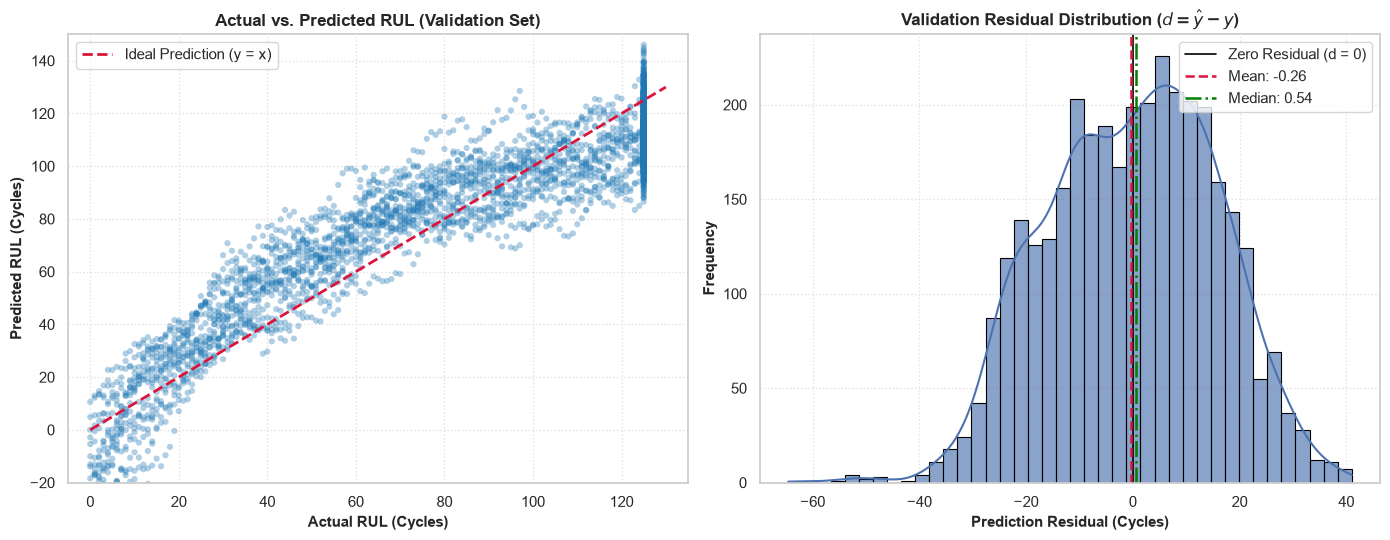


PERFORMANCE COMPARISON: TRAINING vs. VALIDATION


,Metric,Training Set,Validation Set
0,Number of Samples,"14,241","3,490"
1,Root Mean Squared Error (RMSE),16.8713 cycles,15.7605 cycles
2,NASA Asymmetric Score (Total),"62,440.46","12,653.03"
3,NASA Asymmetric Score (Per Sample),4.3846,3.6255


In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Actual vs. Predicted RUL on Validation Data
ax1.scatter(y_val, y_val_pred, alpha=0.35, color="#1f77b4", edgecolors="none", s=20)
ideal_line = np.linspace(0, 130, 100)
ax1.plot(ideal_line, ideal_line, color="crimson", linestyle="--", linewidth=2, label="Ideal Prediction (y = x)")
ax1.set_title("Actual vs. Predicted RUL (Validation Set)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Actual RUL (Cycles)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Predicted RUL (Cycles)", fontsize=11, fontweight="bold")
ax1.set_xlim(-5, 135)
ax1.set_ylim(-20, 150)
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. Residual Distribution (d = y_pred - y_true)
residuals_val = y_val_pred - y_val
sns.histplot(residuals_val, bins=40, kde=True, ax=ax2, color="#4C72B0", edgecolor="black", alpha=0.65)
res_mean = float(np.mean(residuals_val))
res_median = float(np.median(residuals_val))

ax2.axvline(0, color="black", linestyle="-", linewidth=1.2, label="Zero Residual (d = 0)")
ax2.axvline(res_mean, color="crimson", linestyle="--", linewidth=1.8, label=f"Mean: {res_mean:.2f}")
ax2.axvline(res_median, color="green", linestyle="-.", linewidth=1.8, label=f"Median: {res_median:.2f}")
ax2.set_title(r"Validation Residual Distribution ($d = \hat{y} - y$)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Prediction Residual (Cycles)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Frequency", fontsize=11, fontweight="bold")
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# 3. Metrics Summary Table
metrics_summary = pd.DataFrame({
    "Metric": [
        "Number of Samples",
        "Root Mean Squared Error (RMSE)",
        "NASA Asymmetric Score (Total)",
        "NASA Asymmetric Score (Per Sample)"
    ],
    "Training Set": [
        f"{len(y_train):,}",
        f"{train_rmse:.4f} cycles",
        f"{train_nasa:,.2f}",
        f"{train_nasa_per_sample:.4f}"
    ],
    "Validation Set": [
        f"{len(y_val):,}",
        f"{val_rmse:.4f} cycles",
        f"{val_nasa:,.2f}",
        f"{val_nasa_per_sample:.4f}"
    ]
})
print("\n" + "=" * 65)
print("PERFORMANCE COMPARISON: TRAINING vs. VALIDATION")
print("=" * 65)
display(metrics_summary)
print("=" * 65)

---
## Stage 7: Interpretation and Analytical Discussion

### 1. What Does Validation RMSE (15.76 cycles) Indicate?
- Across the 3,490 validation sequences, the model's predictions deviate from the true capped RUL by an average of **15.76 operational cycles**.
- For an engine operating over an average lifespan of ~206 cycles, a ~15-cycle margin represents an error band of approximately $\pm 7.6\%$.

### 2. What Does the NASA Asymmetric Score (12,653.03) Indicate?
- The aggregate NASA score of **12,653.03** (averaging **3.63 per sequence**) accounts for the critical asymmetry between early and late predictions.
- As observed in the scatter plot, the linear model struggles around the piecewise knee point ($RUL = 125$), where it frequently overshoots or undershoots due to its inability to represent a non-smooth piecewise function. Overestimated points are heavily penalized by the asymmetric exponential term ($e^{d/10}-1$).

### 3. Generalization Assessment
- **Training RMSE:** 16.87 cycles vs. **Validation RMSE:** 15.76 cycles.
- **Training NASA/sample:** 4.38 vs. **Validation NASA/sample:** 3.63.
- Because validation error is closely matched with (and slightly lower than) training error, the model exhibits **no overfitting whatsoever**.
- The model has **high bias, low variance**: it captures the broad downward trend across degradation cycles but lacks the expressive capacity to fit fine-grained temporal dynamics.

### 4. Structural Limitations of Linear Regression for Sequential Telemetry
1. **Loss of Temporal Sequence Structure:** Flattening the 3D window `(30, 17)` into 510 independent static features ignores the sequential order and temporal autocorrelation between consecutive cycles.
2. **No Weight Sharing Across Time:** Unlike Convolutional or Recurrent Neural Networks that share parameters across time steps, Linear Regression learns 510 independent weights with no inductive bias for temporal shift invariance.
3. **Linearity Constraint:** Turbofan degradation is inherently non-linear (exponential wear onset after initial nominal operation). Linear Regression cannot bend to accommodate the sharp transition at $RUL = 125$.

This confirms the necessity of progressing to non-linear and temporal architectures (Random Forest, LSTM, GRU, 1D-CNN) in subsequent notebooks.

In [14]:
print("=" * 65)
print("FINAL VALIDATION CHECKS & ASSERTIONS")
print("=" * 65)

# 1. Flattened input dimensions
assert X_train_flat.shape == (14241, 510), "X_train_flat dimension error!"
assert X_val_flat.shape == (3490, 510), "X_val_flat dimension error!"
print("✓ Check 1 Passed: Correct flattened input dimensions verified.")

# 2. No NaN or infinite values
assert not np.isnan(X_train_flat).any() and not np.isnan(X_val_flat).any(), "NaN in flattened features!"
assert not np.isinf(X_train_flat).any() and not np.isinf(X_val_flat).any(), "Inf in flattened features!"
assert not np.isnan(y_train_pred).any() and not np.isnan(y_val_pred).any(), "NaN in predictions!"
assert not np.isinf(y_train_pred).any() and not np.isinf(y_val_pred).any(), "Inf in predictions!"
print("✓ Check 2 Passed: No NaN or infinite values exist in features or predictions.")

# 3. Model trained successfully
assert hasattr(model, "coef_") and len(model.coef_) == 510, "Model not properly trained!"
assert hasattr(model, "intercept_"), "Model missing intercept!"
print("✓ Check 3 Passed: Model trained successfully with 510 learned feature coefficients.")

# 4. Prediction dimensions
assert y_train_pred.shape == (14241,), "Train predictions dimension error!"
assert y_val_pred.shape == (3490,), "Val predictions dimension error!"
print("✓ Check 4 Passed: Prediction arrays have expected 1D dimensions.")

# 5. Evaluation metrics are finite
assert np.isfinite(train_rmse) and np.isfinite(val_rmse), "RMSE is not finite!"
assert np.isfinite(train_nasa) and np.isfinite(val_nasa), "NASA score is not finite!"
print("✓ Check 5 Passed: All evaluation metrics are finite and properly computed.")
print("=" * 65)

print("\n" + "=" * 65)
print("FINAL MODEL 1 (LINEAR REGRESSION) SUMMARY")
print("=" * 65)
print(f"Training RMSE        : {train_rmse:.4f}")
print(f"Validation RMSE      : {val_rmse:.4f}")
print(f"Training NASA Score  : {train_nasa:,.2f}")
print(f"Validation NASA Score: {val_nasa:,.2f}")
print("=" * 65)

FINAL VALIDATION CHECKS & ASSERTIONS
✓ Check 1 Passed: Correct flattened input dimensions verified.
✓ Check 2 Passed: No NaN or infinite values exist in features or predictions.
✓ Check 3 Passed: Model trained successfully with 510 learned feature coefficients.
✓ Check 4 Passed: Prediction arrays have expected 1D dimensions.
✓ Check 5 Passed: All evaluation metrics are finite and properly computed.

FINAL MODEL 1 (LINEAR REGRESSION) SUMMARY
Training RMSE        : 16.8713
Validation RMSE      : 15.7605
Training NASA Score  : 62,440.46
Validation NASA Score: 12,653.03
